In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/student_mental_health.csv")

# 01 - Exploratory Data Analysis (EDA)
# 1.1 -  Initial Data Review

In [3]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [4]:
df.shape

(2000, 17)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [6]:
df.dtypes

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [7]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


# 2. Logical Inconsistencies

In [8]:
social_media_invalid = df[df["Social_Media_Hours"] > df["Screen_Time_Hours"]]

print("Number of inconsistent student: ", len(social_media_invalid))

social_media_invalid[
    ["Social_Media_Hours" , "Screen_Time_Hours"]
].head()


Number of inconsistent student:  37


,Social_Media_Hours,Screen_Time_Hours
78,5.0,4.9
168,5.6,5.3
209,7.5,7.3
278,6.0,5.1
382,5.3,4.1


In [9]:
age_study_check = df[
    ((df["Age"] < 18) & (df["Year_of_Study"] >= 3))
    | ((df["Age"] < 20) & (df["Year_of_Study"]) == 5)
]

print("Number of unusual cases:", len(age_study_check))

age_study_check[["Age", "Year_of_Study"]].sort_values(by=["Age", "Year_of_Study"] , ascending=False).head()

Number of unusual cases: 36


,Age,Year_of_Study
37,17,5
442,17,5
520,17,5
526,17,5
635,17,5


In [13]:
age_invalide = df[
    (df["Age"] < 16) | (df["Age"] > 60)
]

print("Number of invalide Age: ", len(age_invalide))

age_invalide["Age"].sort_values(ascending=False)

Number of invalide Age:  0


Series([], Name: Age, dtype: int64)

In [14]:
ranges = {
    "Sleep_Hours": (0, 24),
    "Study_Hours_Per_Week": (0, 168),
    "GPA": (0, 4),
    "Social_Media_Hours": (0, 24),
    "Screen_Time_Hours": (0, 24),
    "Financial_Stress": (0, 10),
    "Family_Support": (0, 10),
    "Attendance_Rate": (0, 100),
}

for column , (minimun , maximun) in ranges.items():
    invalid = df[
        (df[column] < minimun) | (df[column] > maximun)
    ]

    print(f"{column}: {len(invalid)} invalid columns")

Sleep_Hours: 0 invalid columns
Study_Hours_Per_Week: 0 invalid columns
GPA: 0 invalid columns
Social_Media_Hours: 0 invalid columns
Screen_Time_Hours: 0 invalid columns
Financial_Stress: 0 invalid columns
Family_Support: 0 invalid columns
Attendance_Rate: 0 invalid columns


# 3. Data Quality Audit
# 3.1 Missing Values Analysis

In [ ]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing values" : missing_values,
    "missing_percentage" : missing_percentage,
})

missing_summary = missing_summary[missing_summary["Missing values"] > 0]
missing_summary.sort_values(by="Missing values" , ascending=False)

,Missing values,missing_percentage
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


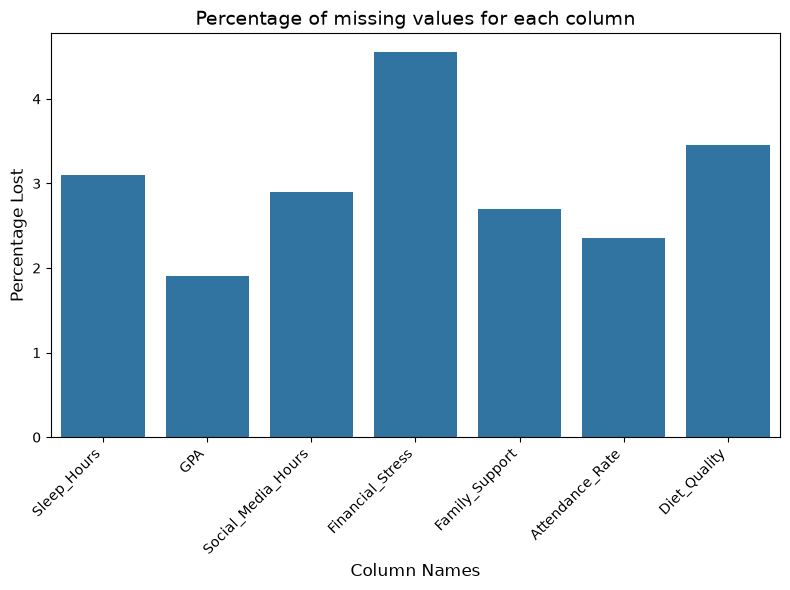

In [ ]:
plt.figure(figsize=(8 , 6))

sns.barplot(x = missing_summary.index , y= missing_summary.missing_percentage)

plt.xticks(rotation = 45 , ha = "right")
plt.title("Percentage of missing values for each column", fontsize = 14)
plt.xlabel("Column Names", fontsize = 12)
plt.ylabel("Percentage Lost" , fontsize = 12)

plt.tight_layout()
plt.show()

# 3.2 - Duplicates Analysis

In [ ]:
print("Duplicated row: " , df.duplicated().sum())

Duplicated row:  0


# 3.3 - Unique Values Analysis

In [ ]:
df.nunique().sort_values(ascending=False)

Student_ID                        2000
Attendance_Rate                    313
Study_Hours_Per_Week               284
GPA                                182
Screen_Time_Hours                   95
Financial_Stress                    87
Family_Support                      82
Social_Media_Hours                  71
Sleep_Hours                         66
Age                                 13
Year_of_Study                        5
Gender                               3
Physical_Activity                    3
Diet_Quality                         3
Mental_Health_Risk                   3
Part_Time_Job                        2
Previous_Mental_Health_History       2
dtype: int64

In [ ]:
categoricle_columns = [
    "Gender",
    "Physical_Activity",
    "Part_Time_Job",
    "Diet_Quality",
    "Previous_Mental_Health_History",
    "Mental_Health_Risk"
]

for colum in categoricle_columns:
    print(df[colum].value_counts(dropna=False))
    print("\n")


Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64


Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64


Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64


Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64


Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64


Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64




# 2.3 - Initial Outlier Inspection

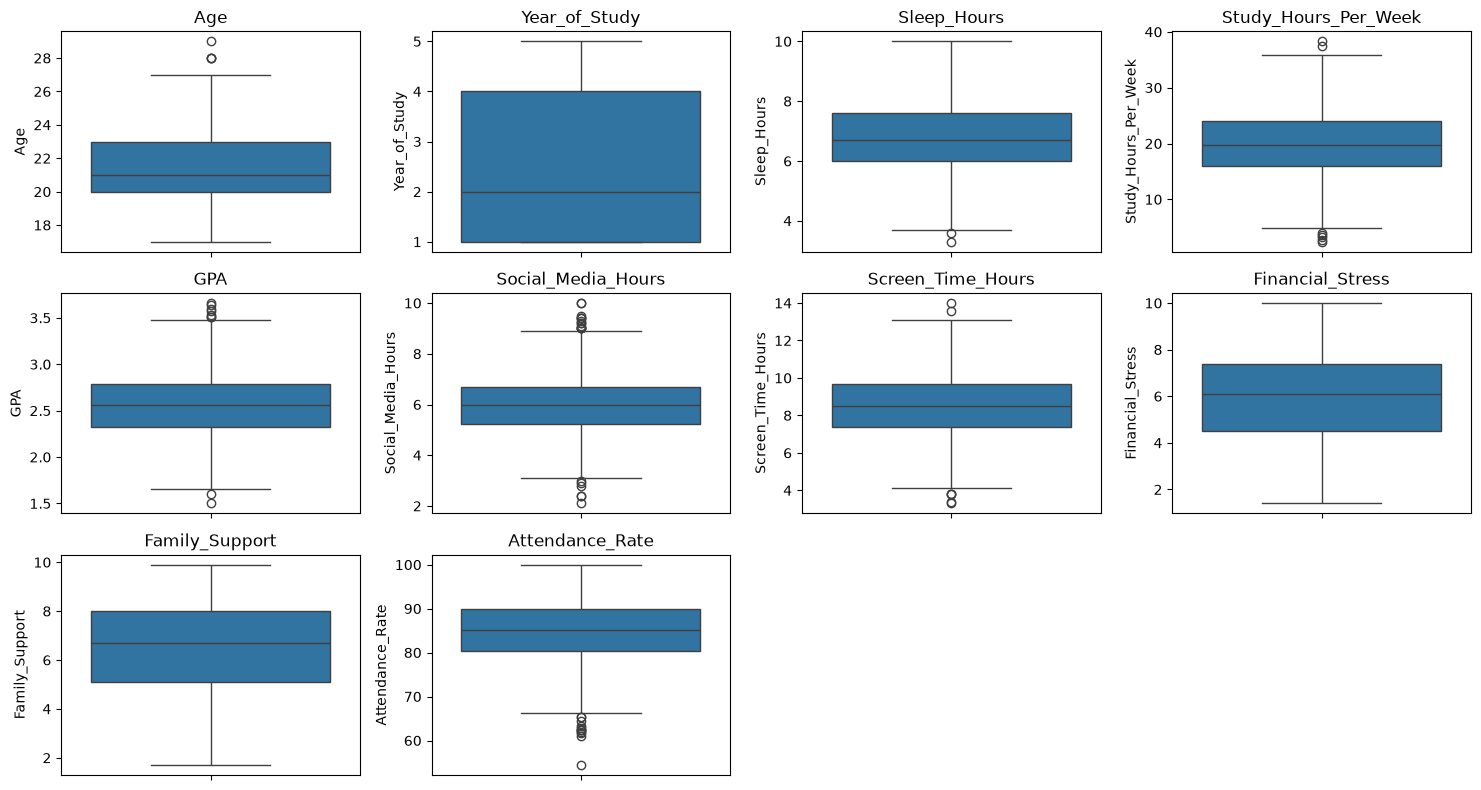

In [ ]:
numerical_columns = df.select_dtypes(include="number").columns

plt.figure(figsize=(15 , 8))

for i , column in enumerate(numerical_columns , 1):
    plt.subplot(3 , 4 , i)
    sns.boxplot(y = df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [ ]:
outlier_results = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1 

    lower_bound = Q1 - 1.5 * IQR 
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) | (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature" : column,
        "Lower Bound" : lower_bound,
        "Upper Bound" : upper_bound,
        "Outliers Count" : len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)
outlier_summary

,Feature,Lower Bound,Upper Bound,Outliers Count
0,Age,15.5000,27.5000,4
1,Year_of_Study,-3.5000,8.5000,0
2,Sleep_Hours,3.6000,10.0000,2
3,Study_Hours_Per_Week,4.0000,36.0000,7
4,GPA,1.6150,3.4950,9
5,Social_Media_Hours,3.0125,8.9125,20
6,Screen_Time_Hours,3.9500,13.1500,7
7,Financial_Stress,0.1500,11.7500,0
8,Family_Support,0.7500,12.3500,0
9,Attendance_Rate,65.7500,104.5500,12


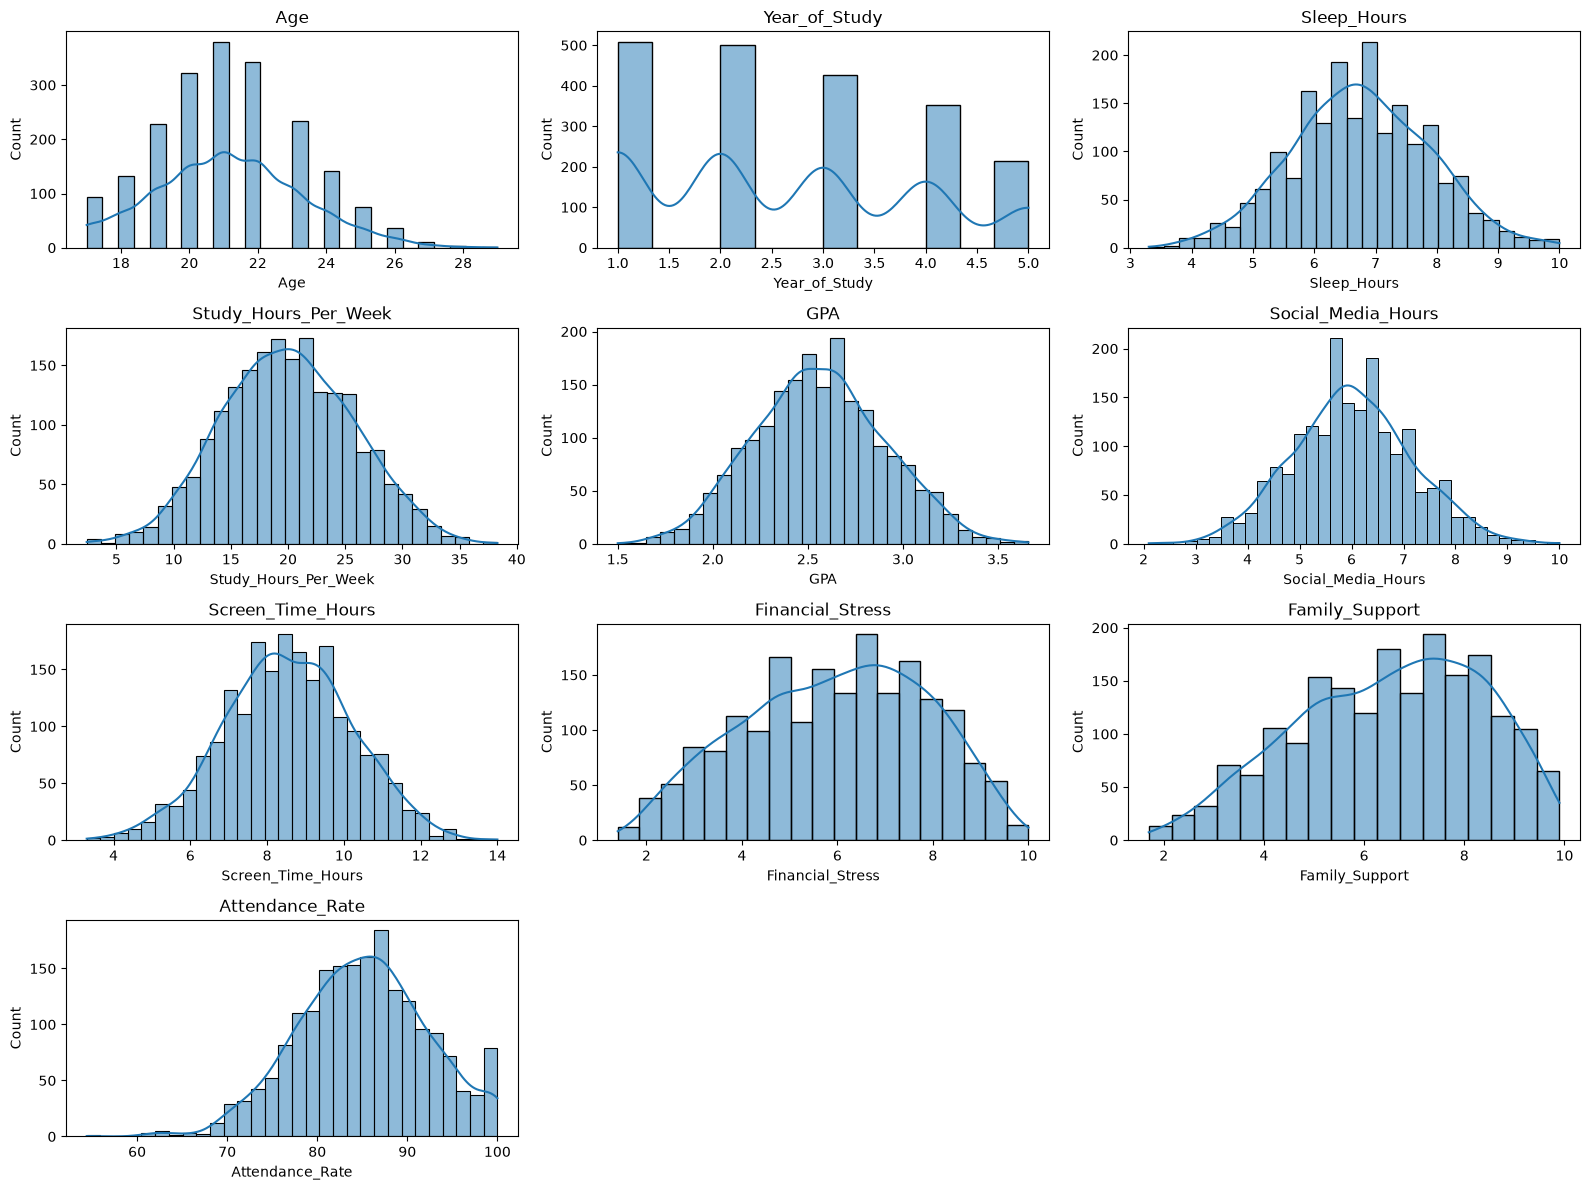

In [ ]:
plt.figure(figsize=(16 , 12))

for i , column in enumerate(numerical_columns , 1):
    plt.subplot(4 , 3 , i)

    sns.histplot(data=df , x = column , kde = True)

    plt.title(column)

plt.tight_layout()
plt.show()

# 3.4 - Feature vs Target Analysis

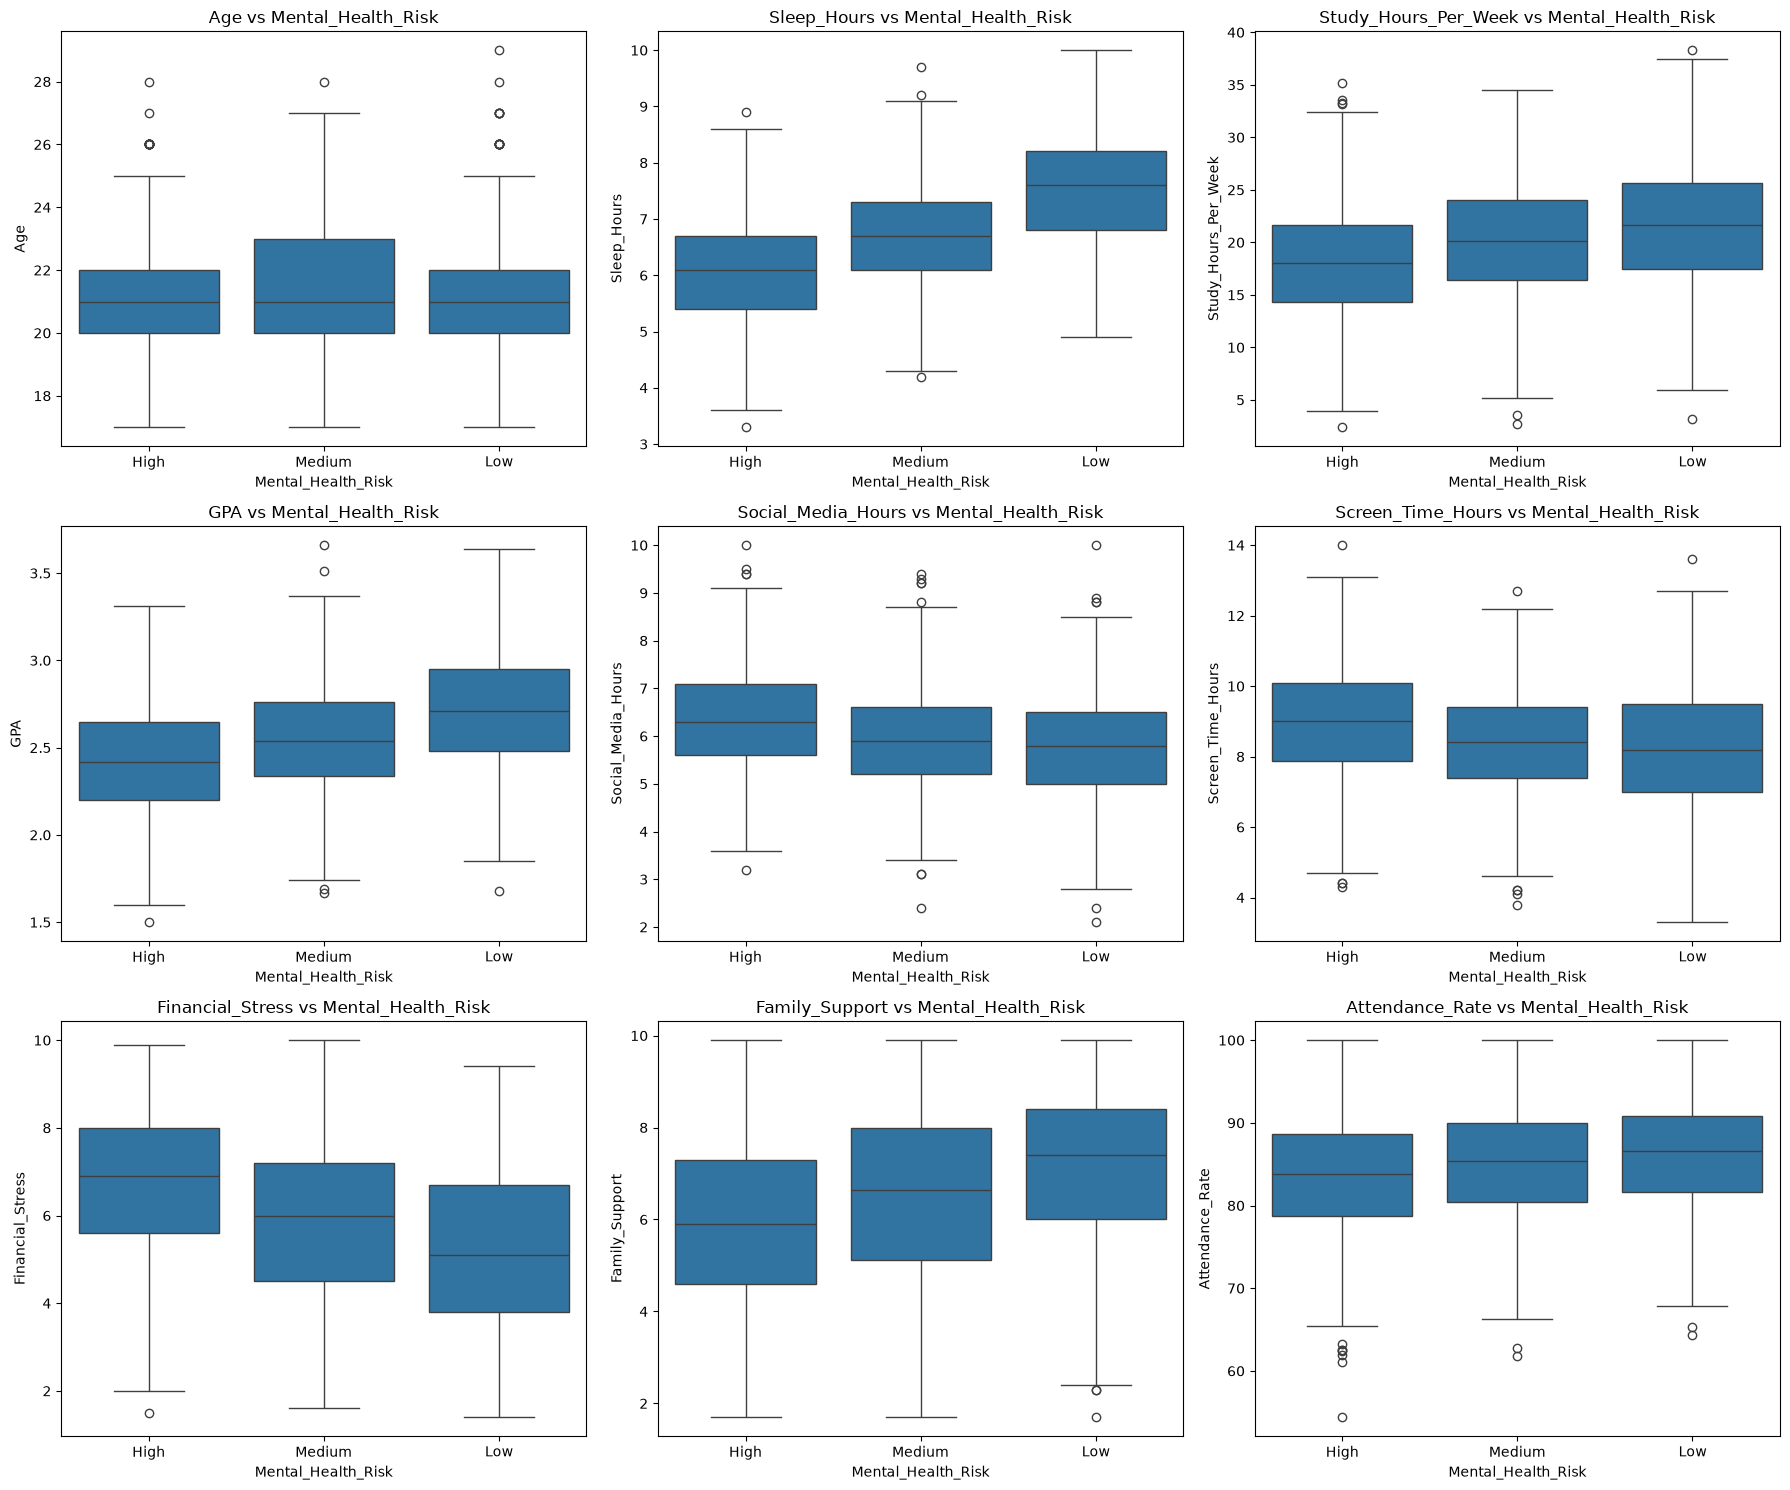

In [ ]:
numerical_features = [
    "Age",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate"
]

plt.figure(figsize=(18 , 15))

for i , column in enumerate(numerical_features , 1):
    plt.subplot(3 , 3 , i)
    sns.boxplot(
        data = df,
        x = "Mental_Health_Risk",
        y = column
    )

    plt.title(f"{column} vs Mental_Health_Risk")

plt.tight_layout()
plt.show()


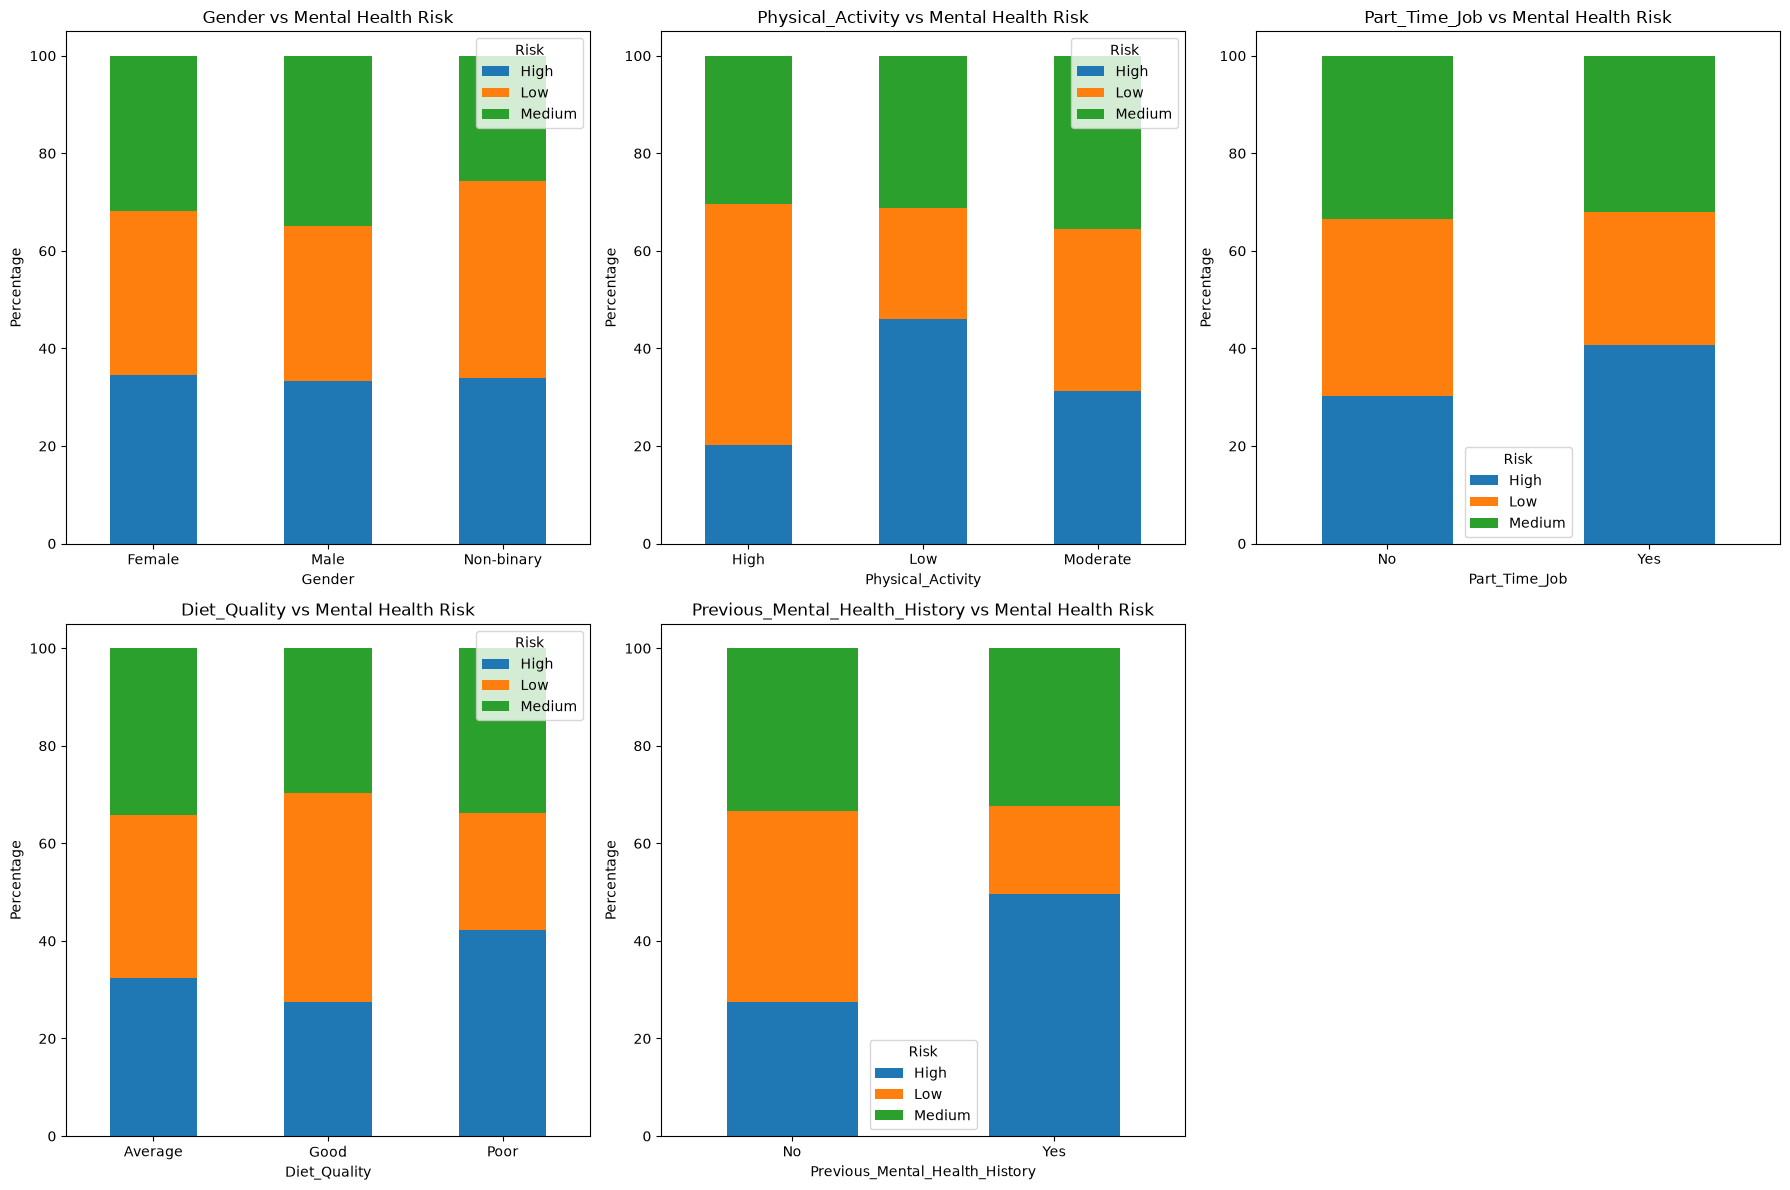

In [16]:
categorical_features = [
    "Gender",
    "Physical_Activity",
    "Part_Time_Job",
    "Diet_Quality",
    "Previous_Mental_Health_History"
]

plt.figure(figsize = (18 , 12))

for i , column in enumerate(categorical_features , 1):
    plt.subplot(2, 3, i)

    risk_distribution = pd.crosstab(
        df[column],
        df["Mental_Health_Risk"],
        normalize="index",
    ) * 100

    risk_distribution.plot(
        kind = "bar",
        stacked= True,
        ax = plt.gca()
    )

    plt.title(f"{column} vs Mental Health Risk")
    plt.xlabel(column)
    plt.ylabel("Percentage")
    plt.xticks(rotation=0)
    plt.legend(title="Risk")

plt.tight_layout()
plt.show()

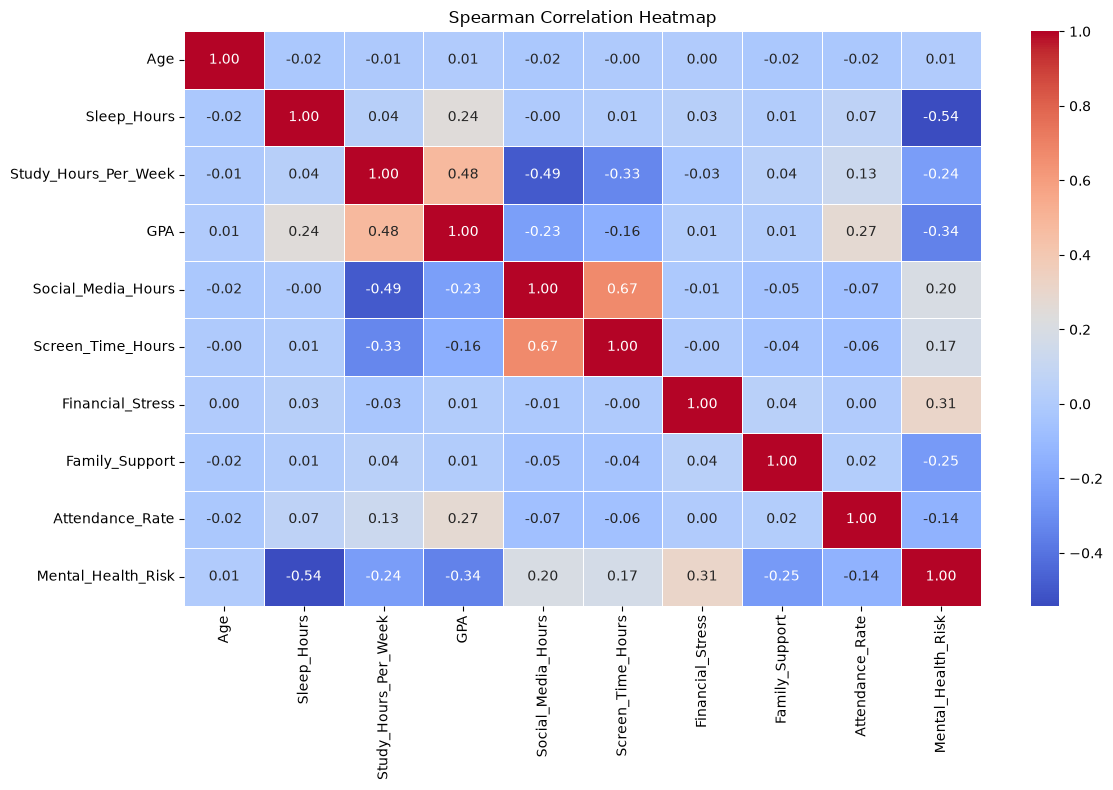

In [ ]:
df_corr = df[numerical_features].copy()

df_corr["Mental_Health_Risk"] = df["Mental_Health_Risk"].map(
    {
        "Low": 0,
        "Medium": 1,
        "High": 2,
    }
)

correlation_matrix = df_corr.corr(method="spearman")

plt.figure(figsize=(12 , 8))

sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f" , linewidths=0.5)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()